In [1]:
!pip install optuna
!pip install MLstatkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 9.0 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
from MLstatkit import Delong_test
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split, cross_val_score, ParameterGrid, StratifiedKFold
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, brier_score_loss, roc_curve, accuracy_score, recall_score, confusion_matrix, f1_score, classification_report, brier_score_loss
from sklearn.utils import resample
import xgboost as xgb
import shap
import optuna
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.metrics import AUC
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop

# 1. Import dataset y filtrado

### Filtrado de pacientes

In [ ]:
df_form1 = pd.read_csv('/content/drive/MyDrive/TFG Paula Hernández - colab/NSCISC-public-data-2021/f1_public_2021.csv', low_memory=False)
df_form2 = pd.read_csv('/content/drive/MyDrive/TFG Paula Hernández - colab/NSCISC-public-data-2021/f2_public_2021.csv', low_memory=False)

In [ ]:
df_form1.shape, df_form2.shape

((35675, 658), (131217, 325))

In [ ]:
# filtramos Date of First System Admission entre 2000 y 2019
# nos quedamos con todos los pacientes desde enero 2000 hasta diciembre 2019 aunque el paper
# original utilice solo hasta mayo 2019 porque solo existen datos de año, no de mes

# Etiología traumática válida (no NaN) -> " primary diagnosis of SCI admitted to an SCI model system center"

df_form1_filtered = df_form1[(df_form1['AAdmDt'] >= 2000) & (df_form1['AAdmDt'] <= 2019) & (df_form1["ATrmEtio"].notna())]

df_form1_filtered.shape

(14395, 658)

In [ ]:
# form2 tiene un formulario por cada paciente cada x años (hay varios form2 por cada paciente)
# en este caso, nos interesan solo los formularios para ver el estado de los pacientes tras 1 año

df_form2_1year = df_form2[df_form2['BYear'] == 1]


In [ ]:
# antes de unir los dos df en uno, comprobamos que no hay columnas con el mismo nombre

set(df_form1.columns) & set(df_form2.columns)

{'UniID'}

In [ ]:
# unimos los df en uno
df_filtered_1 = df_form1_filtered.merge(df_form2_1year, how='left', on='UniID')

# nos quedamos con los que no tienen la variable de salida 'no válida' o NaN
# = 9 -> unknown
df_filtered_1 = df_filtered_1[df_filtered_1['BWlk150'] != 9.0]
df_filtered_1 = df_filtered_1.dropna(subset=['BWlk150'])

df_filtered_1 = df_filtered_1.reset_index(drop=True)

In [ ]:
df_filtered_1.head()

,ANSysAdM,ARbAdDtM,ASDDAc2R,ASDDDurR,AI2ADays,AI2RhADa,AHDaSyAc,AHDaSyRb,ASex,APResInj,...,BMotLvLf,BPrNuFRt,BPrNuFLf,BNurLvl,BAnalSns,BVolSphn,BASAImp,BNImpCat,BIntvDt,BAnExDt
0,9,1,0,0,14,30,16,32,2,1,...,X99,X99,X99,X99,9.0,9.0,U,9.0,2005.0,2005.0
1,9,1,0,0,10,22,12,35,1,1,...,X99,X99,X99,X99,9.0,9.0,U,9.0,2004.0,2004.0
2,9,1,0,0,7,42,35,29,1,1,...,X99,X99,X99,X99,9.0,9.0,U,9.0,2004.0,NaN
3,9,1,0,0,9,13,4,53,1,1,...,X99,X99,X99,X99,9.0,9.0,U,9.0,2005.0,NaN
4,9,1,0,0,27,52,25,25,1,1,...,X99,X99,X99,X99,9.0,9.0,U,9.0,2003.0,NaN


In [ ]:
# "excluded due to unavailability of light touch and pin prick testing"
# variables predictoras se obtuvieron "during the acute rehabilitation period", nos quedamos con los sufijos RR (right) o RL (left)
# según el data dictionary, hay 3 tipos de columnas: each dermatome, subtotal right and left, total

# LT = Light Touch (tacto ligero)
# PP = Pin Prick (pinchazo)
# RR = Rehab Rehabilitation Admission (al ingreso en rehabilitación)


# CÓDIGOS:
# each dermatome: 8 Not Testable, unable to test; infants; cast; amputee.   9 Unknown, Not Done, No System rehab admission (for Rehab admit position only)
# subtotal: 88 Not Testable, unable to test; infants; cast; amputee.   99 Unknown, Not Done, No System rehab admission (for Rehab admit position only)
# total: 888 Not Testable, unable to test; infants; cast; amputee.   999 Unknown, Not Done, No System rehab admission (for Rehab admit position only)



cols_dermatome = [
    "AASAC5RR", "AASAC6RR", "AASAC7RR", "AASAC8RR",
    "AASAT1RR", "AASAL2RR", "AASAL3RR", "AASAL4RR", "AASAL5RR", "AASAS1RR", "AASAStRR",
    "AASAC5RL", "AASAC6RL", "AASAC7RL", "AASAC8RL",
    "AASAT1RL", "AASAL2RL", "AASAL3RL", "AASAL4RL", "AASAL5RL", "AASAS1RL", "AASAStRL",
    "ALTC2RR", "ALTC3RR", "ALTC4RR", "ALTC5RR", "ALTC6RR", "ALTC7RR", "ALTC8RR",
    "ALTT1RR", "ALTT2RR", "ALTT3RR", "ALTT4RR", "ALTT5RR", "ALTT6RR", "ALTT7RR", "ALTT8RR",
    "ALTT9RR", "ALTT10RR", "ALTT11RR", "ALTT12RR",
    "ALTL1RR", "ALTL2RR", "ALTL3RR", "ALTL4RR", "ALTL5RR",
    "ALTS1RR", "ALTS2RR", "ALTS3RR", "ALTS45RR",
    "ALTC2LR", "ALTC3LR", "ALTC4LR", "ALTC5LR", "ALTC6LR", "ALTC7LR", "ALTC8LR",
    "ALTT1LR", "ALTT2LR", "ALTT3LR", "ALTT4LR", "ALTT5LR", "ALTT6LR", "ALTT7LR", "ALTT8LR",
    "ALTT9LR", "ALTT10LR", "ALTT11LR", "ALTT12LR",
    "ALTL1LR", "ALTL2LR", "ALTL3LR", "ALTL4LR", "ALTL5LR",
    "ALTS1LR", "ALTS2LR", "ALTS3LR", "ALTS45LR",
    "APPC2RR", "APPC3RR", "APPC4RR", "APPC5RR", "APPC6RR", "APPC7RR", "APPC8RR",
    "APPT1RR", "APPT2RR", "APPT3RR", "APPT4RR", "APPT5RR", "APPT6RR", "APPT7RR", "APPT8RR",
    "APPT9RR", "APPT10RR", "APPT11RR", "APPT12RR",
    "APPL1RR", "APPL2RR", "APPL3RR", "APPL4RR", "APPL5RR",
    "APPS1RR", "APPS2RR", "APPS3RR", "APPS45RR",
    "APPC2LR", "APPC3LR", "APPC4LR", "APPC5LR", "APPC6LR", "APPC7LR", "APPC8LR",
    "APPT1LR", "APPT2LR", "APPT3LR", "APPT4LR", "APPT5LR", "APPT6LR", "APPT7LR", "APPT8LR",
    "APPT9LR", "APPT10LR", "APPT11LR", "APPT12LR",
    "APPL1LR", "APPL2LR", "APPL3LR", "APPL4LR", "APPL5LR",
    "APPS1LR", "APPS2LR", "APPS3LR", "APPS45LR"
]

cols_subtotal = ['ALTSubRR', 'ALTSubLR', "APPSubRR", "APPSubLR"]

cols_total = ["AASATotR", "ALTTotRh"]


# nos quitamos filas que tengan ALGÚN valor NO VÁLIDO en dichas columnas
df_filtered_2 = df_filtered_1[~df_filtered_1[cols_dermatome].isin([9, 8]).any(axis=1)]
df_filtered_2 = df_filtered_2[~df_filtered_2[cols_subtotal].isin([99, 88]).any(axis=1)]
df_filtered_2 = df_filtered_2[~df_filtered_2[cols_total].isin([999, 888]).any(axis=1)]


# quitamos también valores nan
df_filtered_2 = df_filtered_2.dropna(axis=0, subset=cols_dermatome + cols_subtotal + cols_total)


print(f"{len(df_filtered_2)} filas tienen examen sensorial/motor válido")


4057 filas tienen examen sensorial/motor válido


### Comprobación estadísticas demográficas

Como tenemos un número de pacientes diferente que el estudio original (4057 vs. 4523) , vamos a comprobar las estadísticas demográficas de nuestro conjunto de datos y compararlas con las establecidas por el estudio original. Si vemos que estas son razonablemente equivalentes, aceptaremos el nuevo conjunto de datos como el original.

NOTA: En el paper viene una tabla con todas las estadísticas, yo he calculado las estadísticas que vienen ESCRITAS en el paper.


In [ ]:
# porcentaje sexo hombres (1) original = 79.7% frente a 79.6% de nuestros datos

df_filtered_2['ASex'].value_counts() / len(df_filtered_2)

,count
ASex,
1,0.796401
2,0.202859
3,0.000739


In [ ]:
# porcentaje raza caucásica (1) original = 70.7% frente a 69.6% de nuestros datos

df_filtered_2['ARace'].value_counts() / len(df_filtered_2)


,count
ARace,
1,0.696081
2,0.223564
5,0.038452
4,0.020458
9,0.009613
3,0.008134
7,0.003697


In [ ]:
# los años de las personas están agrupados como string cuando se trata de niños menores de 15 años,
# el paper original establece que, quitando estos, la edad mediana son 41 años
# nuestros datos tienen como edad mediana 40 años

age_col_float = pd.to_numeric(df_filtered_2['AInjAge'], errors='coerce').dropna()

age_col_float.median()

40.0

In [ ]:
# paper: The most common etiology of injury was vehicular accident (39.6%)
# en nuestro análisis vehicular accident es también la categoría más común, con un 38.5%

# agrupamos los códigos según sus categorías
vehicular_codes = [1, 2, 3, 4, 5, 6, 7, 8, 9]
violence_codes = [10,11,12,15]
sports_codes = [20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 70, 71, 72, 73, 74, 75, 76, 77, 78]
falls_codes = [30,31]
pedestrian_code = [40]
medical_code = [50]

groups = {
    "vehicular": vehicular_codes,
    "violence": violence_codes,
    "sports": sports_codes,
    "falls": falls_codes,
    "pedestrian": pedestrian_code,
    "medical": medical_code
}

accident_etiology = pd.Series({
    name: df_filtered_2['ATrmEtio'][df_filtered_2['ATrmEtio'].isin(codes)].count()
    for name, codes in groups.items()
})

accident_etiology / len(df_filtered_2)

,0
vehicular,0.385260
violence,0.142716
sports,0.091940
falls,0.320187
pedestrian,0.008134
medical,0.043628


In [ ]:
# the most common neurologic level of injury was cervical (60.8%)

# esta puede ser una de las categorías que más difiere del dataset original (49.6% vs 60.8%)

neurologic_injury = df_filtered_2['ASLRhbRt'].str[0].value_counts()

neurologic_injury / len(df_filtered_2)

,count
ASLRhbRt,
C,0.495686
T,0.384274
L,0.073946
X,0.036973
S,0.009120


Dado este análisis, tomaremos como suficientemnete parecido el dataset que tenemos actualmente comparado con el que se utilizó en el estudio original.

In [ ]:
df = df_filtered_2

outcome = 'BWlk150'

asia_ingreso = "AASAImAd" -- ASIA acute medical care (for day-1 admissions only

asia_rehab = 'AASAImRb -- at admission to rehab (for all patients admitted to rehab)

In [ ]:
print(f'Tenemos {len(df)} pacientes, de los cuales {(df['BWlk150'] == 1).sum()} ambulan y {(df['BWlk150'] == 0).sum()} no')

Tenemos 4057 pacientes, de los cuales 1724 ambulan y 2333 no


### Selección de variables (columnas)

En el paper viene una tabla con un nombre identificativo de las diferentes columnas y sus 'factor levels', es decir, los valores que pueden tomar dichas columnas. En este cuaderno se utilizaran exactamente los mismos nombres que en el paper original por cuestiones de interpretación y comodidad.

In [ ]:
# Injury Etiology Category

vehicular_codes = [1, 2, 3, 4, 5, 6, 7, 8, 9]
violence_codes = [10,11,12,15]
sports_codes = [20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 70, 71, 72, 73, 74, 75, 76, 77, 78]
falls_codes = [30,31]
pedestrian_code = [40]
medical_code = [50]

etiology_map = {}
for category, codes in [
    ("vehicular", vehicular_codes),
    ("violence", violence_codes),
    ("sports", sports_codes),
    ("falls", falls_codes),
    ("pedestrian", pedestrian_code),
    ("medical", medical_code)
]:
    for code in codes:
        etiology_map[code] = category

df['ATrmEtio'] = df['ATrmEtio'].map(etiology_map).fillna('Other')

# bmi, pasamos peso de libras a kg y altura de pulgadas a m

df['bmi'] = np.where(
    (df['AHghtRhb'] != 999) & (df['AWghtRhb'] != 999),
    (df['AWghtRhb'] / 2.205) / ((df['AHghtRhb'] * 2.54 / 100) ** 2),
    np.nan
)

# rellenamos los valores NaN de la columna 'bmi' según la mediana de las personas de su mismo sexo
# y grupo de edad (consulta con profesionales)
df['bmi'] = df['bmi'].fillna(
    df.groupby(['ASex', 'AInjAge'])['bmi'].transform('median')
)

En la siguiente celda se seleccionan las columnas que se utilizan en el experimento (tabla del paper). Se ha comprobado que estas columnas son las correctas a través del material adicional del dataset NSCISC-public-data-2021 (Data Dictionary y Variable List).

Como podemos observar, todas las columnas empiezan con la letra 'A' menos las 4 últimas (endpoints), esto indica que las columnas son del formulario 1 y, por lo tanto, son datos medidos en el momento del accidente, no con posterioridad.

In [ ]:
# todas columnas del form I, menos las de at 1-year

cols_experiment = ['ASex', 'ARace', 'AHispnic', 'AMarStIj', 'AEducLvl', 'APrLvlSt', 'ATrmEtio', 'AVertInj', 'AAsscInj',
                   'ASpinSrg', 'AUMVAdm', 'ANurLvlR', 'AVoSphRb', 'AAnSnRhb', 'AASAImRb', 'ANCatRhb', 'AAnxiety', 'ADepress',
                   'ADiabete', 'AHypTen', 'AHypLip', 'AArthr', 'AAlcNbDr', 'AInjAge', 'bmi', 'AHDaSyAc', 'AI2RhADa',
                   'AASAL2RL', 'AASAL3RL', 'AASAL4RL', 'AASAL5RL', 'AASAS1RL', 'AASAL2RR', 'AASAL3RR', 'AASAL4RR', 'AASAL5RR', 'AASAS1RR',
                   'ALTL1LR', 'ALTL2LR', 'ALTL3LR', 'ALTL4LR', 'ALTL5LR', 'ALTS1LR', 'ALTS2LR', 'ALTS3LR', 'ALTS45LR',
                   'ALTL1RR', 'ALTL2RR', 'ALTL3RR', 'ALTL4RR', 'ALTL5RR', 'ALTS1RR', 'ALTS2RR', 'ALTS3RR', 'ALTS45RR',
                   'APPL1LR', 'APPL2LR', 'APPL3LR', 'APPL4LR', 'APPL5LR', 'APPS1LR', 'APPS2LR', 'APPS3LR', 'APPS45LR',
                   'APPL1RR', 'APPL2RR', 'APPL3RR', 'APPL4RR', 'APPL5RR', 'APPS1RR', 'APPS2RR', 'APPS3RR', 'APPS45RR',
                   'BWlk150', 'BWlkBlck', 'BWlkStps', 'BASAImp'

                   ]

In [ ]:
variables = [
    # --- Categorical variables ---
    "Sex",
    "Race",
    "Hispanic",
    "Marital Status",
    "Education",
    "Employment Status",
    "Injury Etiology Category",
    "Vertebral Injury",
    "Associated Injury",
    "Spinal Surgery",
    "Mechanical Ventilation",
    "Neuro Level",
    "Voluntary Anal Contraction",
    "Deep Anal Pressure",
    "ASIA at Rehab",
    "Neuro Impairment",
    "Anxiety",
    "Depression",
    "Diabetes",
    "Hypertension",
    "Hyperlipidemia",
    "Arthritis",
    "Alcohol: # drinks per day",

    # --- Continuous variables ---
    "Age at Injury",
    "BMI",
    "LOS Acute Care",
    "Injury to Rehab Admission",

    # --- ASIA Sub-Tests ---
    # Motor Score
    "Motor Score Left L2",
    "Motor Score Left L3",
    "Motor Score Left L4",
    "Motor Score Left L5",
    "Motor Score Left S1",
    "Motor Score Right L2",
    "Motor Score Right L3",
    "Motor Score Right L4",
    "Motor Score Right L5",
    "Motor Score Right S1",

    # Sensory: LT
    "Sensory LT Left L1",
    "Sensory LT Left L2",
    "Sensory LT Left L3",
    "Sensory LT Left L4",
    "Sensory LT Left L5",
    "Sensory LT Left S1",
    "Sensory LT Left S2",
    "Sensory LT Left S3",
    "Sensory LT Left S4-5",
    "Sensory LT Right L1",
    "Sensory LT Right L2",
    "Sensory LT Right L3",
    "Sensory LT Right L4",
    "Sensory LT Right L5",
    "Sensory LT Right S1",
    "Sensory LT Right S2",
    "Sensory LT Right S3",
    "Sensory LT Right S4-5",

    # Sensory: Pin Prick
    "Sensory PP Left L1",
    "Sensory PP Left L2",
    "Sensory PP Left L3",
    "Sensory PP Left L4",
    "Sensory PP Left L5",
    "Sensory PP Left S1",
    "Sensory PP Left S2",
    "Sensory PP Left S3",
    "Sensory PP Left S4-5",
    "Sensory PP Right L1",
    "Sensory PP Right L2",
    "Sensory PP Right L3",
    "Sensory PP Right L4",
    "Sensory PP Right L5",
    "Sensory PP Right S1",
    "Sensory PP Right S2",
    "Sensory PP Right S3",
    "Sensory PP Right S4-5",

    # --- Endpoints ---
    "Walk 150 ft at 1-year",
    "Walk One Block at 1-year",
    "Walk Flight of Stairs at 1-year",
    "ASIA Score at 1-year"
]


In [ ]:
df_final = df[cols_experiment]
df_final.columns = variables

### Convertir a NaN valores no válidos

En el Data Dictionary podemos encontrar cada columna y el significado de los códigos. En la mayoría, el código número 7 significa 'declined/doesn't know' y el número 9 'unknown'. Así, establecemos las celdas que tengan esos códigos como 'NaN'.

In [ ]:
# 7 = declined/doesn't know 9=unknown
df_final.loc[(df_final['Sex'] == 9), 'Sex'] = np.nan
df_final.loc[(df_final['Race'] == 7)|(df_final['Race'] == 9), 'Race'] = np.nan
df_final.loc[(df_final['Hispanic'] == 7)|(df_final['Hispanic'] == 9), 'Hispanic'] = np.nan
df_final.loc[(df_final['Marital Status'] == 9), 'Marital Status'] = np.nan
df_final.loc[(df_final['Education'] == 9), 'Education'] = np.nan
df_final.loc[(df_final['Employment Status'] == 99), 'Employment Status'] = np.nan
df_final.loc[(df_final["Injury Etiology Category"] == 99), "Injury Etiology Category"] = np.nan
df_final.loc[(df_final['Vertebral Injury'] == 9), 'Vertebral Injury'] = np.nan
df_final.loc[(df_final['Associated Injury'] == 9), 'Associated Injury'] = np.nan
df_final.loc[(df_final["Spinal Surgery"] == 9), "Spinal Surgery"] = np.nan
df_final.loc[(df_final["Mechanical Ventilation"] == 9), "Mechanical Ventilation"] = np.nan
df_final.loc[(df_final["Neuro Level"] == 'X99')|(df_final["Neuro Level"] == '703')|(df_final["Neuro Level"] == "304"), "Neuro Level"] = np.nan
df_final.loc[(df_final['Voluntary Anal Contraction'] == 8)|(df_final['Voluntary Anal Contraction'] == 9), 'Voluntary Anal Contraction'] = np.nan
df_final.loc[(df_final['Deep Anal Pressure'] == 8)|(df_final['Deep Anal Pressure'] == 9), 'Deep Anal Pressure'] = np.nan

# En el experimento original, no aparece el ASIA 'E' como un factor level, es decir, no lo tienen en cuenta
df_final.loc[(df_final['ASIA at Rehab'] == 'U')|(df_final['ASIA at Rehab'] == 'E'), 'ASIA at Rehab'] = np.nan

df_final.loc[(df_final['Neuro Impairment'] == 9), 'Neuro Impairment'] = np.nan
df_final.loc[(df_final['Anxiety'] == 7)|(df_final['Anxiety'] == 9), 'Anxiety'] = np.nan
df_final.loc[(df_final['Depression'] == 7)|(df_final['Depression'] == 9), 'Depression'] = np.nan
df_final.loc[(df_final['Diabetes'] == 7)|(df_final['Diabetes'] == 9), 'Diabetes'] = np.nan
df_final.loc[(df_final['Hypertension'] == 7)|(df_final['Hypertension'] == 9), 'Hypertension'] = np.nan
df_final.loc[(df_final['Hyperlipidemia'] == 7)|(df_final['Hyperlipidemia'] == 9), 'Hyperlipidemia'] = np.nan
df_final.loc[(df_final['Arthritis'] == 7)|(df_final['Arthritis'] == 9), 'Arthritis'] = np.nan
df_final.loc[(df_final["Alcohol: # drinks per day"] == 7)|(df_final["Alcohol: # drinks per day"] == 9), "Alcohol: # drinks per day"] = np.nan

df_final.loc[(df_final['Age at Injury'] == 999), 'Age at Injury'] = np.nan

mapeo_edad = {
    '13-14y': (13+14)/2.0,
    '6-12y': (6+12)/2.0,
    '88+y': 90
}

df['Age at Injury'] = df_final['Age at Injury'].replace(mapeo_edad).astype('float')
df_final['Age at Injury'] = df_final['Age at Injury'].replace(mapeo_edad).astype('float')

# en el paper aclaran que no hay ningún paciente con LOS Acute Care > 242
df_final.loc[df_final['LOS Acute Care'] > 242, 'LOS Acute Care'] = np.nan
df_final.loc[(df_final['Injury to Rehab Admission'] == 888), 'Injury to Rehab Admission'] = np.nan

# Motor score, sensory light touch y sensory pin prick ya nos lo hemos quitado

df_final.loc[(df_final["Walk One Block at 1-year"] == 9), "Walk One Block at 1-year"] = np.nan
df_final.loc[(df_final["Walk Flight of Stairs at 1-year"] == 9), "Walk Flight of Stairs at 1-year"] = np.nan

df_final.loc[(df_final["ASIA Score at 1-year"] == 'U'), "ASIA Score at 1-year"] = np.nan



/tmp/ipykernel_205/632582135.py:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Age at Injury'] = df_final['Age at Injury'].replace(mapeo_edad).astype('float')


### Conversión de tipos

#### Variables categoricas a One-Hot Encoding


In [ ]:
# Mapeo categóricas

# Sex
sex_map = {
    1: "Male",
    2: "Female",
    3: "Other, Transgender"
}

df_final['Sex'] = df_final['Sex'].map(sex_map)


# Race
race_map = {
    1: "White, Caucasian",
    2: "Black, African American",
    3: "American Indian, Alaska Native",
    4: "Asian, Pacific Islander",
    5: "Other Race, Multiracial"
}

df_final['Race'] = df_final['Race'].map(race_map)

# Hipanic -> ya está con 0 (Not Hispanic) / 1 (Hispanic)

# Marital Status

marital_status_map = {
    1: "Single, Never Married",
    2: "Married",
    3: "Divorced",
    4: "Separated",
    5: "Widowed",
    6: "Other, Unclassified",
    7: "Significant Other, Partner, Unmarried Couple"
}

df_final['Marital Status'] = df_final['Marital Status'].map(marital_status_map)

# Education

education_map = {
    1: "8th grade or less",
    2: "9th-11th grade",
    3: "High School Diploma/GED",
    4: "Associate Degree",
    5: "Bachelor Degree",
    6: "Master Degree",
    7: "Doctorate",

}

df_final['Education'] = df_final['Education'].map(education_map)


# Employment Status

employment_status_mapping = {
    1: "Working",
    2: "Homemaker",
    3: "Working", # On-the-job training
    4: "Working", # Sheltered workshop
    5: "Retired",
    6: "Student",
    7: "Unemployed",
    8: "Retired",
    9: "Retired",
    10: "Other"
}

df_final['Employment Status'] = df_final['Employment Status'].map(employment_status_mapping)


# Injury Etiology -> ya está mapeado

# Neuro Level

map_neuro_level = {
    "C": "Cervical",
    "T": "Thoracic",
    "L": "Lumbar",
    "S": "Sacral"
}

df_final["Neuro Level"] = df_final["Neuro Level"].str[0].map(map_neuro_level)

# Neuro Impairment

neuro_impairment_mapping = {
    1: "Paraplegia, incomplete",
    2: "Paraplegia, complete",
    3: "Paraplegia, minimal deficit",
    4: "Tetraplegia, incomplete",
    5: "Tetraplegia, complete",
    6: "Tetraplegia, minimal deficit"
}

df_final["Neuro Impairment"] = df_final["Neuro Impairment"].map(neuro_impairment_mapping)

# Number of Alcohol Drinks a day

def map_alcohol(x):
    if pd.isna(x):
        return pd.NA
    elif x in [1, 2]:
        return "1 or 2"
    elif x in [3, 4]:
        return "3 or 4"
    elif x in [5, 6]:
        return "5 or 6"
    elif 7 <= x <= 9:
        return "7 to 9"
    elif x >= 10:
        return "10 or more"
    else:
        return "None"


df_final['Alcohol: # drinks per day'] = df_final['Alcohol: # drinks per day'].map(map_alcohol)


/tmp/ipykernel_205/2828435180.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Sex'] = df_final['Sex'].map(sex_map)
/tmp/ipykernel_205/2828435180.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Race'] = df_final['Race'].map(race_map)
/tmp/ipykernel_205/2828435180.py:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org

In [ ]:
df_final.dtypes.value_counts()


,count
float64,66
object,11


In [ ]:
cols_categoricas = df_final.columns[df_final.dtypes == 'object']

print(cols_categoricas)

df_final = pd.get_dummies(df_final, columns=cols_categoricas, dtype=int)

Index(['Sex', 'Race', 'Marital Status', 'Education', 'Employment Status',
       'Injury Etiology Category', 'Neuro Level', 'ASIA at Rehab',
       'Neuro Impairment', 'Alcohol: # drinks per day',
       'ASIA Score at 1-year'],
      dtype='object')


#### Variables Yes/No a One-Hot Encoding

Para poder replicar el experimento exactamente como es, necesitamos convertir las variables de Yes/No del dataset a dos columnas distintas con One-Hot Encoding. Esto es porque, fijándonos en los materalies complementarios del paper, encontramos una tabla con la importancia de las variables en la regresión logística donde aparecen 'Mechanical_Ventilation_RehabYNNo' y 'Mechanical_Ventilation_RehabYNYes' como dos columnas separadas.

In [ ]:
cols_yes_no = ['Hispanic', 'Vertebral Injury', 'Associated Injury', 'Spinal Surgery',
               'Mechanical Ventilation', 'Voluntary Anal Contraction', 'Deep Anal Pressure', 'Anxiety',
               'Depression', 'Diabetes', 'Hypertension', 'Hyperlipidemia', 'Arthritis']

df_final[cols_yes_no] = df_final[cols_yes_no].astype(object).replace({0: 'No', 1: 'Yes'})
df_final = pd.get_dummies(df_final, columns=cols_yes_no, dtype=int)


### Imputación de valores nulos

Dado que el dataset SIN valores NaN tiene los valores no válidos con números muy dispares/muy altos lo cual puede llegar a confusión por parte de los modelos, decidimos poner todos esos valores como -1 para tener cierta "unanimidad" en este aspecto. Así, tras comprobar que ninguna columna tiene ningún valor negativo, sabemos que a partir de ahora los valores -1 se corresponden todos con antiguos valores no válidos.

In [ ]:
(df_final == -1).sum().sum()


np.int64(0)

In [ ]:
df_final_imputed = df_final.copy(deep=True)
df_final_imputed = df_final.fillna(-1)
df_final = df_final.reset_index(drop=True)

In [ ]:
(df_final_imputed == -1).sum().sum()

np.int64(2170)

In [ ]:
df_final['Walk 150 ft at 1-year'].isna().sum()

np.int64(0)

**df_final -> con -1 donde debe haber NaN**

**df_final_not_imputed -> con NaN**

### Estadísticas finales

In [ ]:
df_final.describe(include=['int', 'float'])

,Age at Injury,BMI,Hispanic_No,Hispanic_Yes,Vertebral Injury_No,Vertebral Injury_Yes,Associated Injury_No,Associated Injury_Yes,Spinal Surgery_No,Spinal Surgery_Yes,...,Depression_No,Depression_Yes,Diabetes_No,Diabetes_Yes,Hypertension_No,Hypertension_Yes,Hyperlipidemia_No,Hyperlipidemia_Yes,Arthritis_No,Arthritis_Yes
count,4057.0,4057.0,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,...,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000
mean,41.975598,26.815005,0.859749,0.126941,0.176978,0.820557,0.648509,0.346315,0.168105,0.829431,...,0.837318,0.136308,0.899680,0.089721,0.586394,0.150604,0.619423,0.113877,0.613754,0.119546
std,17.895548,6.513366,0.347290,0.332948,0.381697,0.383770,0.477495,0.475854,0.374005,0.376179,...,0.369121,0.343157,0.300464,0.285818,0.492540,0.357706,0.485589,0.317701,0.486948,0.324470
min,9.0,12.451804,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,26.0,22.464594,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,...,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,40.0,25.784559,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,...,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
75%,57.0,29.831951,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000,...,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
max,90.0,94.101473,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
df_final.duplicated().sum() # no hay filas duplicadas

np.int64(0)

### Guardar datasets

In [ ]:
df_final.to_csv('dataset-original.csv', index=False)
df_final_imputed.to_csv('dataset-original-imputed.csv', index=False)

### Separación train, test

In [3]:
df = pd.read_csv('/content/drive/MyDrive/TFG Paula Hernández - colab/dataset-original.csv')
df_imputed = pd.read_csv('/content/drive/MyDrive/TFG Paula Hernández - colab/dataset-original-imputed.csv')

**IMPORTANTE**: No *data leakage*

In [4]:
df = df.drop(columns= ["Walk One Block at 1-year",
    "Walk Flight of Stairs at 1-year", 'ASIA Score at 1-year_A',
       'ASIA Score at 1-year_B', 'ASIA Score at 1-year_C',
       'ASIA Score at 1-year_D', 'ASIA Score at 1-year_E'])

df_imputed = df_imputed.drop(columns= ["Walk One Block at 1-year",
    "Walk Flight of Stairs at 1-year",
    'ASIA Score at 1-year_A',
       'ASIA Score at 1-year_B', 'ASIA Score at 1-year_C',
       'ASIA Score at 1-year_D', 'ASIA Score at 1-year_E'])



**Separación train/test**: Como en el paper original esta separación es atleatoria y de 80/20 se hará igual aquí. Aún así, se mirará que la columna a predecir esté más o menos en la misma proporción en ambos conjuntos.

In [5]:
df_x = df.drop(columns=['Walk 150 ft at 1-year'])
df_y = df['Walk 150 ft at 1-year']

df_x_imputed = df_imputed.drop(columns=['Walk 150 ft at 1-year'])
df_y_imputed = df_imputed['Walk 150 ft at 1-year']

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df_x, df_y, test_size=0.2, random_state=52)

X_train_imputed, X_test_imputed, y_train_imputed, y_test_imputed = train_test_split(
    df_x_imputed, df_y_imputed, test_size=0.2, random_state=52)

In [7]:
porc_original = (df_y == 0).mean() * 100
porc_train = (y_train == 0).mean() * 100
porc_test = (y_test == 0).mean() * 100

print(f'El porcentaje de NO es el dataset original es {porc_original}%')
print(f'Dicho porcentaje es {porc_train}% en train y {porc_test}% en test')

El porcentaje de NO es el dataset original es 57.50554596992852%
Dicho porcentaje es 57.68875192604006% en train y 56.77339901477833% en test


# 2. Modelos de clasificación

#### Métricas utilizadas para evaluar el rendimiento de los modelos

**Área bajo la curva ROC-AUC:** Probabilidad de que el modelo asigne un score más alto a un caso positivo aleatorio que a uno negativo. Indica qué tan bueno es el modelo separando las clases.

**Accuracy:** Porcentaje total de aciertos sobre el total de casos. Puede ser engañosa en datasets desbalanceados.

**Recall:** Penaliza los falsos negativos (preicho como negativo pero realmente positivo). Es especialmente importante en medicina ya que no queremos no detectar algo importante.

**F1 Score:** Media entre precision y recall. Penaliza falsos positivos y falsos negativos.

**Brier Loss:** MSE entre la probabilidad prevista y el resultado real. Es decir, es menor si la probabilidad predicha es cercana al resultado real. Mide "lo claro que lo tiene el modelo".

**Bootstrap**: Remuestreo estadístico para medir la incertidumbre. Consiste en generar múltiples versiones del set de test (con reemplazo) para calcular un intervalo de confianza. Mide la robustez del modelo frente a variaciones en los datos.

**Matriz de confusión:** Muestra el número de verdaderos positivos, verdaderos negativos, falsos positivos y falsos negativos.

In [8]:
def bootstrap_ci(y_true, y_pred, n_bootstraps=1000, ci=95):
    scores = []
    ind = np.arange(len(y_true))

    for i in range(n_bootstraps):
        # remuestreo con reemplazo (puede salir un dato de test más de una vez)
        boot_ind = resample(ind, replace=True, n_samples=len(ind))

        y_true_boot = y_true[boot_ind]
        y_pred_boot = y_pred[boot_ind]

        # saltamos la iteración si coge solo una clase (0/1) en el sample
        if len(np.unique(y_true_boot)) < 2:
            continue

        score = roc_auc_score(y_true_boot, y_pred_boot)
        scores.append(score)

    # calcular percentiles
    alpha = (100 - ci) / 2.0
    lower_bound = np.percentile(scores, alpha)
    upper_bound = np.percentile(scores, 100 - alpha)
    original_score = roc_auc_score(y_true, y_pred)

    return [lower_bound, upper_bound]



### Clasificación logística con ElasticNet

En el paper original utilizan la librería "glmnet" de R. En Python tenemos su librería homónima que es un wrapper de la de R. Al existir incompatibilidades con versiones de numpy y python, utilizamos el modelo ElasticNet de sklearn.


''
The ENPLR hyperparameter alpha was tuned via grid search and the largest lambda value within 1 standard error from the minimum was selected.
''

Al no especificar en ningún momento entre qué valores se buscan alpha y lambda, por tiempo de ejecución, en vez de GridSearch utilizaremos Optuna, que no prueba todas las combinaciones posibles si no un número limitado de posibilidades.

Hacemos un estudio Optuna para los parámetros y para lambda (C).

In [ ]:
def objective(trial):
    l1_ratio = trial.suggest_float('l1_ratio', 0.0, 1.0)
    C = trial.suggest_float('C', 0.001, 1000, log=True)  # log=True da una búsqueda más eficiente

    model = LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        l1_ratio=l1_ratio,
        C=C,
        max_iter=5000,
        class_weight='balanced',
        random_state=42
    )

    model.fit(X_train_imputed,y_train_imputed)
    y_pred = model.predict(X_test_imputed)

    return roc_auc_score(y_test_imputed, y_pred)


study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=10, show_progress_bar=True)


[I 2026-05-28 10:51:31,921] A new study created in memory with name: no-name-1616bba5-b47f-4e8f-9e3c-f2fab64838ad


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-05-28 10:52:06,501] Trial 0 finished with value: 0.8795631940968166 and parameters: {'l1_ratio': 0.020686275387448383, 'C': 0.2370761475755232}. Best is trial 0 with value: 0.8795631940968166.
[I 2026-05-28 10:52:16,346] Trial 1 finished with value: 0.8843712726576066 and parameters: {'l1_ratio': 0.5115948203106571, 'C': 0.007214673531940691}. Best is trial 1 with value: 0.8843712726576066.
[I 2026-05-28 10:52:52,851] Trial 2 finished with value: 0.8820722942197996 and parameters: {'l1_ratio': 0.8745642734737885, 'C': 1.7457463729368425}. Best is trial 1 with value: 0.8843712726576066.
[I 2026-05-28 10:53:30,098] Trial 3 finished with value: 0.8903442905612102 and parameters: {'l1_ratio': 0.1900607405405652, 'C': 0.02528842354973349}. Best is trial 3 with value: 0.8903442905612102.
[I 2026-05-28 10:54:04,972] Trial 4 finished with value: 0.8809876955213181 and parameters: {'l1_ratio': 0.3422504789954751, 'C': 2.803145905436619}. Best is trial 3 with value: 0.8903442905612102.
[

In [9]:
# modelo final
best_model = LogisticRegression(
    penalty='elasticnet',
    solver='saga',
    l1_ratio=0.1900607405405652,
    C=0.02528842354973349,
    max_iter=5000,
    class_weight='balanced',
    random_state=42
)
best_model.fit(X_train_imputed, y_train_imputed)


y_pred_elastic = best_model.predict(X_test_imputed)
y_proba_elastic = best_model.predict_proba(X_test_imputed)[:, 1]

In [ ]:
print("=" * 60)
print("MÉTRICAS")
print("=" * 60)

# C-statistic (AUC-ROC)
roc_auc = roc_auc_score(y_test_imputed, y_pred_elastic)
print(f"ROC_AUC:           {roc_auc:.3f}  (objetivo: 0.931)")

# Accuracy
accuracy = accuracy_score(y_test_imputed,y_pred_elastic)
print(f"Accuracy Score:    {accuracy:.3f}  (objetivo: 0.8707)")

# Recall
recall = recall_score(y_test_imputed, y_pred_elastic)
print(f"Recall:            {recall:.3f}")

# F1
f1 = f1_score(y_test_imputed, y_pred_elastic)
print(f"F1 Score:          {f1:.3f}")

# Brier Score
brier_score = brier_score_loss(y_test_imputed, y_proba_elastic)
print(f"Brier Score:       {brier_score:.3f}")

# intervalo de confianza
low_elastic, up_elastic = bootstrap_ci(y_test_imputed.values, y_pred_elastic)
print(f'El intervalo de confianza de ElasticNet con roc-auc {roc_auc:.5f} al 95% es [{low_elastic:.5f}, {up_elastic:.5f}]')

print("\nClassification Report")
print("-" * 60)
print(classification_report(y_test_imputed, y_pred_elastic))

MÉTRICAS
ROC_AUC:           0.890  (objetivo: 0.931)
Accuracy Score:    0.893  (objetivo: 0.8707)
Recall:            0.872
F1 Score:          0.876
Brier Score:       0.085
El intervalo de confianza de ElasticNet con roc-auc 0.89034 al 95% es [0.86819, 0.91234]

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.90      0.91      0.91       461
           1       0.88      0.87      0.88       351

    accuracy                           0.89       812
   macro avg       0.89      0.89      0.89       812
weighted avg       0.89      0.89      0.89       812



In [15]:
# análisis especial categorías B y C

X_test_BC_imputed = X_test_imputed[(X_test_imputed['ASIA at Rehab_C'] == 1.0) | (X_test_imputed['ASIA at Rehab_B'] == 1.0)]
y_test_BC_imputed = y_test_imputed[X_test_BC_imputed.index]

y_pred_BC_elastic = best_model.predict(X_test_BC_imputed)
y_proba_BC_elastic = best_model.predict_proba(X_test_BC_imputed)[:, 1]

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)

# C-statistic (AUC-ROC)
roc_auc = roc_auc_score(y_test_BC_imputed, y_pred_BC_elastic)
print(f"ROC_AUC:           {roc_auc:.3f}  (objetivo: 0.8032)")

# Accuracy
accuracy = accuracy_score(y_test_BC_imputed,y_pred_BC_elastic)
print(f"Accuracy Score:    {accuracy:.3f}  (objetivo: 0.72)")

# Recall
recall = recall_score(y_test_BC_imputed, y_pred_BC_elastic)
print(f"Recall:            {recall:.3f}")

# F1
f1 = f1_score(y_test_BC_imputed, y_pred_BC_elastic)
print(f"F1 Score:          {f1:.3f}")

# Brier Score
brier_score = brier_score_loss(y_test_BC_imputed, y_proba_BC_elastic)
print(f"Brier Score:       {brier_score:.3f}")

# intervalo de confianza
low_elastic, up_elastic = bootstrap_ci(y_test_BC_imputed.values, y_pred_BC_elastic)
print(f'El intervalo de confianza de ElasticNet con roc-auc {roc_auc:.5f} al 95% es [{low_elastic:.5f}, {up_elastic:.5f}]')

print("\nClassification Report")
print("-" * 60)
print(classification_report(y_test_BC_imputed, y_pred_BC_elastic))

MÉTRICAS
ROC_AUC:           0.783  (objetivo: 0.8032)
Accuracy Score:    0.789  (objetivo: 0.72)
Recall:            0.734
F1 Score:          0.755
Brier Score:       0.153
El intervalo de confianza de ElasticNet con roc-auc 0.78303 al 95% es [0.73143, 0.83296]

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       137
           1       0.78      0.73      0.75       109

    accuracy                           0.79       246
   macro avg       0.79      0.78      0.78       246
weighted avg       0.79      0.79      0.79       246



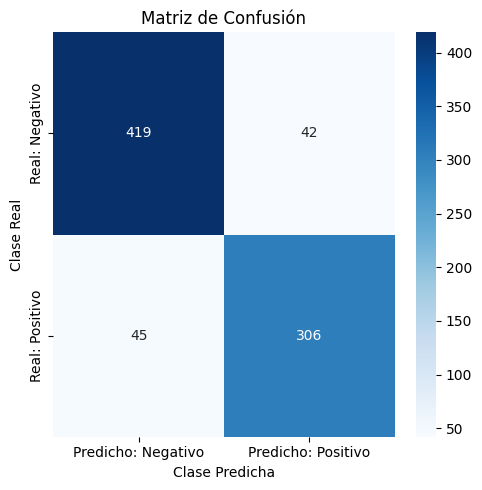

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_elastic)

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Predicho: Negativo', 'Predicho: Positivo'],
            yticklabels=['Real: Negativo', 'Real: Positivo'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

#### Explicabilidad

Tras la buena clasificación de la regresión logística con Elastic Net, procedemos a la explicabilidad. A continuación, veremos qué columnas del dataset contribuyen más a la decisión del modelo.

In [ ]:
coef_df = pd.DataFrame({
    'feature': X_train_imputed.columns,
    'coef': best_model.coef_[0]
}).sort_values(by='coef', key=abs, ascending=False)


In [ ]:
coef_df[abs(coef_df.coef) > 0]

,feature,coef
109,"Neuro Impairment_Tetraplegia, complete",-0.561256
102,ASIA at Rehab_A,-0.560848
79,Education_9th-11th grade,-0.500056
104,ASIA at Rehab_C,0.399576
45,Sensory PP Left L1,0.382483
...,...,...
25,Motor Score Right L5,0.003759
111,"Neuro Impairment_Tetraplegia, minimal deficit",0.003486
40,Sensory LT Right L5,-0.001681
108,"Neuro Impairment_Paraplegia, minimal deficit",0.001049


### Gradient Boosted Machine


"Tuning of the eta (range 0.001–1), maximum tree depth (range 2–10), minimum child weight (range 1–25), and subsample (range 0.25–1)"

In [16]:
def objective(trial):
    # Espacio de búsqueda Bayesiano
    params = {
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'learning_rate': trial.suggest_float('learning_rate', 0.001, 1, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 25),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'subsample': trial.suggest_float('subsample', 0.25, 1.0),
        'random_state': 42
    }

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    aucs = []

    for train_idx, val_idx in cv.split(X_train, y_train):

        X_tr = X_train.iloc[train_idx]
        X_val = X_train.iloc[val_idx]
        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        model = xgb.XGBClassifier(**params)
        model.fit(X_tr, y_tr)

        y_val_proba = model.predict_proba(X_val)[:, 1]
        aucs.append(roc_auc_score(y_val, y_val_proba))

    return np.mean(aucs)


study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

best_model = xgb.XGBClassifier(**study.best_params)
best_model.fit(X_train, y_train)

[I 2026-06-01 11:53:48,630] A new study created in memory with name: no-name-7c56fc20-9853-4628-8682-0f9f2171cd39


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-06-01 11:53:50,786] Trial 0 finished with value: 0.9340442739586032 and parameters: {'learning_rate': 0.013023461079660736, 'min_child_weight': 19, 'max_depth': 3, 'subsample': 0.45022909156888946}. Best is trial 0 with value: 0.9340442739586032.
[I 2026-06-01 11:53:53,158] Trial 1 finished with value: 0.9353396875188513 and parameters: {'learning_rate': 0.00464038242039448, 'min_child_weight': 4, 'max_depth': 4, 'subsample': 0.7271169348775379}. Best is trial 1 with value: 0.9353396875188513.
[I 2026-06-01 11:53:54,178] Trial 2 finished with value: 0.9403191703127532 and parameters: {'learning_rate': 0.038175885304615575, 'min_child_weight': 21, 'max_depth': 8, 'subsample': 0.7381757549433816}. Best is trial 2 with value: 0.9403191703127532.
[I 2026-06-01 11:53:55,079] Trial 3 finished with value: 0.9333210678154351 and parameters: {'learning_rate': 0.39068672632030005, 'min_child_weight': 18, 'max_depth': 7, 'subsample': 0.4278869858148886}. Best is trial 2 with value: 0.9403

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05131011306748495, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=18, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:

y_pred_xgb = best_model.predict_proba(X_test)[:, 1]

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)

# AUC-ROC
roc_auc = roc_auc_score(y_test, y_pred_xgb)
print(f"ROC_AUC:           {roc_auc:.3f}  (objetivo: 0.9235)")

# Accuracy
accuracy = accuracy_score(y_test,y_pred_xgb.round())
print(f"Accuracy Score:    {accuracy:.3f}  (objetivo: 0.8586)")

# Recall
recall = recall_score(y_test, y_pred_xgb.round())
print(f"Recall:            {recall:.3f}")

# F1 Score
f1 = f1_score(y_test, y_pred_xgb.round())
print(f"F1 Score:          {f1:.3f}")

# Brier Score
brier = brier_score_loss(y_test, y_pred_xgb)
print(f"Brier Score Loss:  {brier:.3f}")

# intervalo de confianza
low_gbm, up_gbm = bootstrap_ci(y_test.values, y_pred_xgb)
print(f'El intervalo de confianza de XGBoost con roc-auc {roc_auc:.5f} al 95% es [{low_gbm:.5f}, {up_gbm:.5f}]')


# Classification Report
print("\nClassification Report")
print("-" * 60)
print(classification_report(y_test, y_pred_xgb.round()))


MÉTRICAS
ROC_AUC:           0.951  (objetivo: 0.9235)
Accuracy Score:    0.892  (objetivo: 0.8586)
Recall:            0.875
F1 Score:          0.875
Brier Score Loss:  0.082
El intervalo de confianza de XGBoost con roc-auc 0.95074 al 95% es [0.93615, 0.96421]

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.90      0.90      0.90       461
           1       0.87      0.87      0.87       351

    accuracy                           0.89       812
   macro avg       0.89      0.89      0.89       812
weighted avg       0.89      0.89      0.89       812



In [18]:
# análisis especial categorías B y C

X_test_BC = X_test[(X_test['ASIA at Rehab_C'] == 1.0) | (X_test['ASIA at Rehab_B'] == 1.0)]
y_test_BC = y_test[X_test_BC.index]

y_pred_BC_xgb = best_model.predict(X_test_BC)
y_proba_BC_xgb = best_model.predict_proba(X_test_BC)[:, 1]

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)

# C-statistic (AUC-ROC)
roc_auc = roc_auc_score(y_test_BC, y_pred_BC_xgb)
print(f"ROC_AUC:           {roc_auc:.3f}")

# Accuracy
accuracy = accuracy_score(y_test_BC,y_pred_BC_xgb)
print(f"Accuracy Score:    {accuracy:.3f}")

# Recall
recall = recall_score(y_test_BC, y_pred_BC_xgb)
print(f"Recall:            {recall:.3f}")

# F1
f1 = f1_score(y_test_BC, y_pred_BC_xgb)
print(f"F1 Score:          {f1:.3f}")

# Brier Score
brier_score = brier_score_loss(y_test_BC, y_proba_BC_xgb)
print(f"Brier Score:       {brier_score:.3f}")

# intervalo de confianza
low_xgb, up_xgb = bootstrap_ci(y_test_BC.values, y_pred_BC_xgb)
print(f'El intervalo de confianza de XGBoost con roc-auc {roc_auc:.5f} al 95% es [{low_xgb:.5f}, {up_xgb:.5f}]')

print("\nClassification Report")
print("-" * 60)
print(classification_report(y_test_BC, y_pred_BC_xgb))

MÉTRICAS
ROC_AUC:           0.770
Accuracy Score:    0.780
Recall:            0.679
F1 Score:          0.733
Brier Score:       0.148
El intervalo de confianza de XGBoost con roc-auc 0.77011 al 95% es [0.71595, 0.81842]

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.77      0.86      0.81       137
           1       0.80      0.68      0.73       109

    accuracy                           0.78       246
   macro avg       0.78      0.77      0.77       246
weighted avg       0.78      0.78      0.78       246



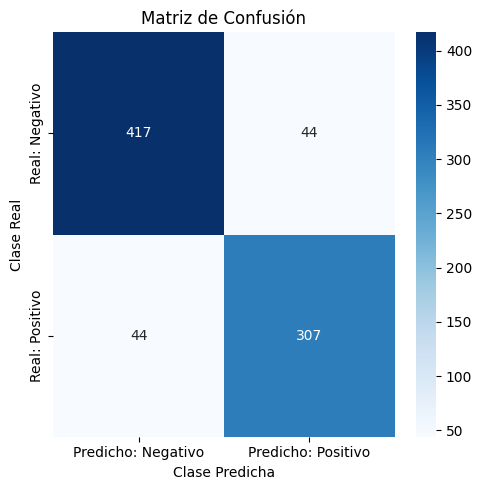

In [ ]:

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_xgb.round())

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Predicho: Negativo', 'Predicho: Positivo'],
            yticklabels=['Real: Negativo', 'Real: Positivo'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

#### Explicabilidad (SHAP)

In [ ]:
# Explainer específico para árboles
explainer = shap.TreeExplainer(best_model)

# shap_values: (n_samples, n_features)
shap_values = explainer.shap_values(X_test)


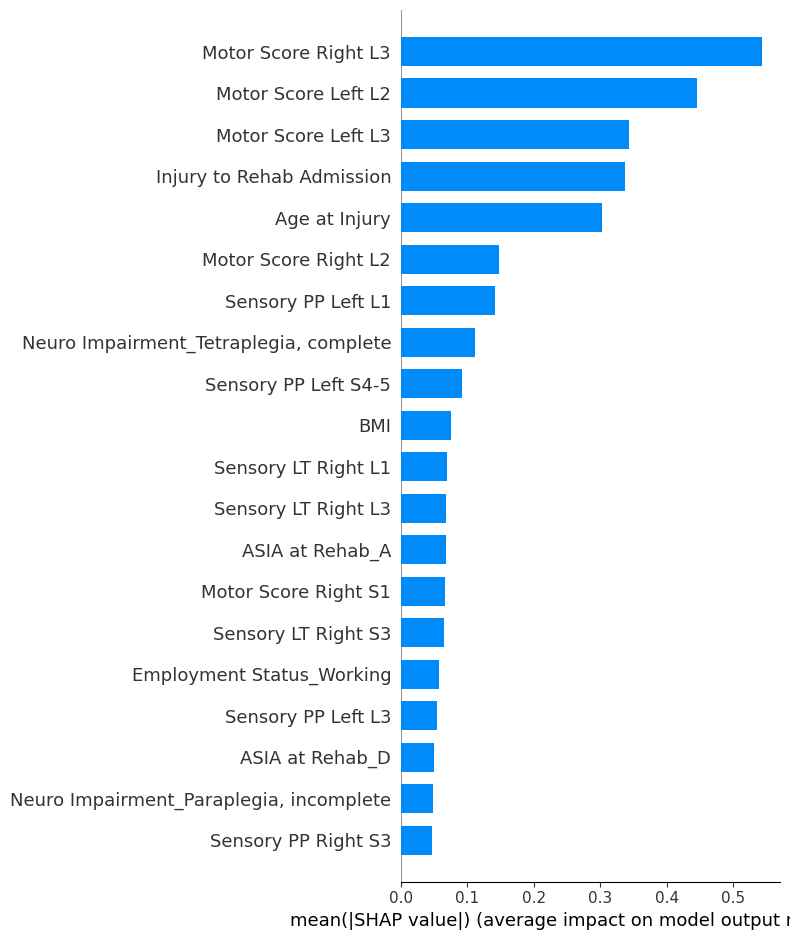

In [ ]:
shap.summary_plot(shap_values, X_test, plot_type="bar")

### ANN

In [20]:
X_train_numpy = X_train_imputed.to_numpy(dtype='float32')
X_test_numpy = X_test_imputed.to_numpy(dtype='float32')
y_train_numpy = y_train_imputed.to_numpy(dtype='float32')
y_test_numpy = y_test_imputed.to_numpy(dtype='float32')

n_features = X_train_numpy.shape[1]


In [ ]:
param_grid = {
    "hidden_nodes": [8, 16, 32, 64, 128, 256],
    "dropout_rate": [0.1, 0.2, 0.3, 0.4],
    "optimizer": ['adam', 'rmsprop'],
    "learning_rate": [0.1, 0.05],
}


# generar todas las combinaciones
all_combinations = list(ParameterGrid(param_grid))
total_combinations = len(all_combinations)

# seleccionar 5% de combinaciones aleatoriamente
n_trials = int(0.05 * total_combinations)
selected_indices = np.random.choice(total_combinations, size=n_trials, replace=False)
selected_combinations = [all_combinations[i] for i in selected_indices]


for params in selected_combinations:

  inputs = Input(shape=(n_features,))

  # Primera capa oculta densa
  x = Dense(params['hidden_nodes'], activation='relu')(inputs)
  x = Dropout(params['dropout_rate'])(x)  # regularización

  # Capa de salida
  outputs = Dense(1, activation='sigmoid')(x)

  # Construir modelo
  model = Model(inputs=inputs, outputs=outputs)

  if params['optimizer'] == 'adam':
    model.compile(optimizer=Adam(learning_rate=params['learning_rate']),
                loss='binary_crossentropy',
                metrics=[AUC(name='auc')])

  if params['optimizer'] == 'rmsprop':
    model.compile(optimizer=RMSprop(learning_rate=params['learning_rate']),
                  loss='binary_crossentropy',
                  metrics=[AUC(name='auc')])

  history = model.fit(
    X_train_numpy, y_train_numpy,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)
  loss, roc_auc = model.evaluate(X_test_numpy, y_test_numpy)
  print("ROC-AUC", roc_auc)


Epoch 1/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - auc: 0.6219 - loss: 4.0929 - val_auc: 0.8799 - val_loss: 0.4791
Epoch 2/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.6296 - loss: 0.6407 - val_auc: 0.5193 - val_loss: 0.7096
Epoch 3/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.6030 - loss: 0.6457 - val_auc: 0.3053 - val_loss: 0.9447
Epoch 4/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.6174 - loss: 0.6218 - val_auc: 0.7342 - val_loss: 0.5808
Epoch 5/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.6654 - loss: 0.7321 - val_auc: 0.5500 - val_loss: 0.6710
Epoch 6/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.6922 - loss: 0.6245 - val_auc: 0.8283 - val_loss: 0.5418
Epoch 7/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - auc: 0.7467 - loss: 0.6015 - val_auc: 0.8350 - val_loss: 0.4718
Epoch 8/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.6366 - loss: 0.6245 - val_auc: 0.7034 - val_loss: 0.5777
Epoch 9/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - auc: 0.6758 - loss:

In [ ]:
print("Mejor combinación (0.9391202926635742):")
print(selected_combinations[3])

Mejor combinación (0.9391202926635742):
{'dropout_rate': 0.1, 'hidden_nodes': 32, 'learning_rate': 0.05, 'optimizer': 'rmsprop'}


In [21]:
# best model
n_features = X_train_numpy.shape[1]

inputs = Input(shape=(n_features,))

x = Dense(32, activation='relu')(inputs)
x = Dropout(0.1)(x)  # regularización

# Capa de salida
outputs = Dense(1, activation='sigmoid')(x)

# Construir modelo
model = Model(inputs=inputs, outputs=outputs)

model.compile(optimizer=RMSprop(learning_rate=0.05),
              loss='binary_crossentropy',
              metrics=[AUC(name='auc')])

history = model.fit(
    X_train_numpy, y_train_numpy,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)



Epoch 1/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - auc: 0.8699 - loss: 1.2093 - val_auc: 0.9016 - val_loss: 0.6035
Epoch 2/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.8983 - loss: 0.4456 - val_auc: 0.9190 - val_loss: 0.4788
Epoch 3/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.9155 - loss: 0.3854 - val_auc: 0.9226 - val_loss: 0.4859
Epoch 4/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.9244 - loss: 0.3653 - val_auc: 0.8794 - val_loss: 0.5699
Epoch 5/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.9232 - loss: 0.3691 - val_auc: 0.9246 - val_loss: 0.3841
Epoch 6/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.9273 - loss: 0.3718 - val_auc: 0.9222 - val_loss: 0.5104
Epoch 7/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.9276 - loss: 0.3541 - val_auc: 0.9240 - val_loss: 0.4097
Epoch 8/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - auc: 0.9266 - loss: 0.3590 - val_auc: 0.9245 - val_loss: 0.3590
Epoch 9/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.9251 - loss:

In [ ]:
# RESULTADOS

y_pred_proba = model.predict(X_test_numpy, verbose=0).flatten()
y_pred_class = (y_pred_proba >= 0.5).astype(int)

roc_auc = roc_auc_score(y_test_numpy, y_pred_proba)
accuracy = accuracy_score(y_test_numpy, y_pred_class)
recall = recall_score(y_test_numpy, y_pred_class)
f1 = f1_score(y_test_numpy, y_pred_class)
brier = brier_score_loss(y_test_numpy, y_pred_proba)
low_rrnn, up_rrnn = bootstrap_ci(y_test_numpy, y_pred_proba)

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)
print(f"ROC_AUC:           {roc_auc:.3f}  (objetivo: 0.9322)")
print(f"Accuracy Score:    {accuracy:.3f}  (objetivo: 0.8729)")
print(f"Recall:            {recall:.3f}")
print(f"F1 Score:          {f1:.3f}")
print(f"Brier Score Loss:  {brier:.3f}")
print(f'El intervalo de confianza de la RRNN con roc-auc {roc_auc:.5f} al 95% es [{low_rrnn:.5f}, {up_rrnn:.5f}]')



MÉTRICAS
ROC_AUC:           0.943  (objetivo: 0.9322)
Accuracy Score:    0.884  (objetivo: 0.8729)
Recall:            0.877
F1 Score:          0.868
Brier Score Loss:  0.095
El intervalo de confianza de la RRNN con roc-auc 0.94344 al 95% es [0.92700, 0.95793]


In [22]:
# análisis especial categorías B y C


X_test_BC_numpy = X_test_BC_imputed.to_numpy(dtype='float32')
y_test_BC_numpy = y_test_BC_imputed.to_numpy(dtype='float32')

y_pred_BC_proba = model.predict(X_test_BC_numpy, verbose=0).flatten()
y_pred_BC_class = (y_pred_BC_proba >= 0.5).astype(int)

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)

# C-statistic (AUC-ROC)
roc_auc = roc_auc_score(y_test_BC_numpy, y_pred_BC_class)
print(f"ROC_AUC:           {roc_auc:.3f}")

# Accuracy
accuracy = accuracy_score(y_test_BC_numpy, y_pred_BC_class)
print(f"Accuracy Score:    {accuracy:.3f}")

# Recall
recall = recall_score(y_test_BC_numpy, y_pred_BC_class)
print(f"Recall:            {recall:.3f}")

# F1
f1 = f1_score(y_test_BC_numpy, y_pred_BC_class)
print(f"F1 Score:          {f1:.3f}")

# Brier Score
brier_score = brier_score_loss(y_test_BC_numpy, y_pred_BC_proba)
print(f"Brier Score:       {brier_score:.3f}")

# intervalo de confianza
low_xgb, up_xgb = bootstrap_ci(y_test_BC_numpy, y_pred_BC_class)
print(f'El intervalo de confianza de XGBoost con roc-auc {roc_auc:.5f} al 95% es [{low_xgb:.5f}, {up_xgb:.5f}]')

print("\nClassification Report")
print("-" * 60)
print(classification_report(y_test_BC_numpy, y_pred_BC_class))

MÉTRICAS
ROC_AUC:           0.767
Accuracy Score:    0.776
Recall:            0.688
F1 Score:          0.732
Brier Score:       0.175
El intervalo de confianza de XGBoost con roc-auc 0.76739 al 95% es [0.71655, 0.82274]

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

         0.0       0.77      0.85      0.81       137
         1.0       0.78      0.69      0.73       109

    accuracy                           0.78       246
   macro avg       0.78      0.77      0.77       246
weighted avg       0.78      0.78      0.77       246



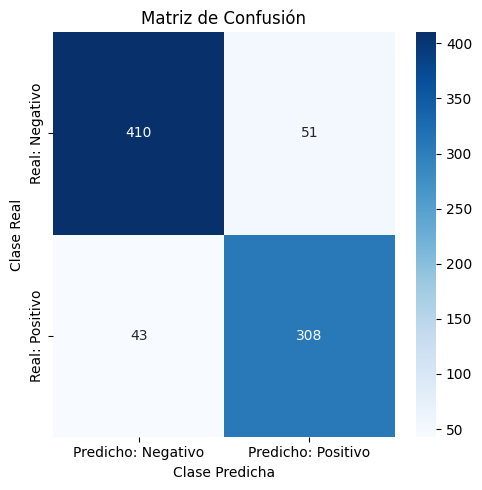

In [ ]:

# Confusion Matrix
cm = confusion_matrix(y_test_numpy, y_pred_class)

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Predicho: Negativo', 'Predicho: Positivo'],
            yticklabels=['Real: Negativo', 'Real: Positivo'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

#### Explicabilidad

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 296ms/step
684/684 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
687/687 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
684/684 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
683/683 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
684/684 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
685/685 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
686/686 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
685/685 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
685/685 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
687/687 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
683/683 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
686/686 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
685/685 ━━━━━

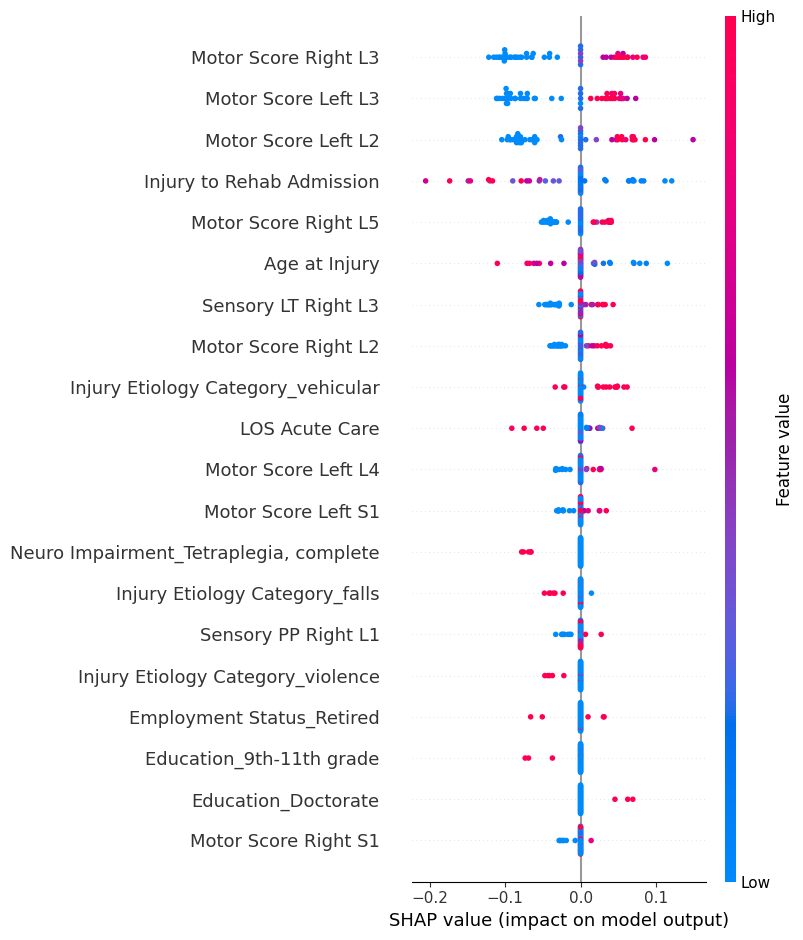

In [ ]:

background = shap.kmeans(X_train_numpy, 10)

def predict_fn(x):
    return model.predict(x).flatten()

# explainer
explainer = shap.KernelExplainer(predict_fn, background)

X_sample = X_test_numpy[:50]
shap_values = explainer.shap_values(X_sample)

shap.summary_plot(shap_values, X_sample, feature_names=X_train.columns.to_list())